# Práctica 1: Predicción de Subscripción a un Producto Bancario
**Asignatura:** Aprendizaje Automático (2025-26)

**Autores:** Pablo Pino Castillo y Alejandro Ros Quesada

## 1. Importación librerías y Configuración Inicial
**Fijado de semilla** (`NIA_SEED = 100522129`)

In [1]:
# %pip install pandas numpy matplotlib scikit-learn joblib streamlit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Antes de nada, fijamos la semilla para reproducir los resultados

In [2]:
NIA_SEED = 100522129
np.random.seed(NIA_SEED)

También, cargamos los datos

In [3]:
ruta_datos = '../datos/bank_29.pkl'
df = pd.read_pickle(ruta_datos)

# Mostramos un ejemplo de cómo son los datos
display(df.tail())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no
11161,34,technician,married,secondary,no,0,no,no,cellular,9,jul,628,1,-1,0,unknown,no


## 2. Análisis Exploratorio de Datos (EDA) Simplificado

In [4]:
# 1. Tamaño del dataset
print("===== 1. Variables e instancias =====")
print(f"Número de instancias (filas): {df.shape[0]}")
print(f"Número de variables (columnas): {df.shape[1]}\n")

# 2. Tipos de variables (categóricas, ordinales o numéricas)
print("===== 2. Tipos de variables =====")
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print(f"Numéricas: {num_cols}")
print(f"Categóricas: {cat_cols}")
print("Ordinales: ['education']\n\nBasándonos en el apéndice de datos, la variable 'education' tiene un orden lógico (primaria < secundaria < universitaria), por lo que se tratará como ordinal.\n")

# 3. Variables categóricas con alta cardinalidad (>10 de valores únicos)
print("===== 3. Alta cardinalidad(>10 valores únicos) =====")
card = [col for col in cat_cols if df[col].nunique() > 10]
print(f"Variables categóricas con alta cardinalidad: {card}\n")

# 4. Qué variables tienen valores faltantes y cuántos
print("===== 4. Valores faltantes =====")
sum_nulos = df.isnull().sum()
nulos = sum_nulos[sum_nulos > 0]

if nulos.empty:
    print("No hay ninguna variable con valores faltantes (nulos)\n")
else:
    print("Variables con valores faltantes y su cantidad:\n")
    print(nulos.to_string(), "\n\t")


# 5. Si hay columnas constantes o columnas de ID
print("===== 5. Columnas constantes o de id =====")
cols_const = [col for col in df.columns if df[col].nunique() == 1]
cols_id = [col for col in df.columns if df[col].nunique() == df.shape[0]]

print(f"Columnas constantes: {cols_const}")
print(f"Columnas de ID: {cols_id}\n")


# 6. Regresión o clasificación, y si está desbalancead
print("===== 6. Problema de Regresión o Clasificación y balanceo")

print("Como el objetivo es predecir si un cliente suscribirá un depósito ('deposit'), se trata de un problema de CLASIFICACIÓN.")
print("Veamos el porcentaje de cada clase para comprobar si está desbalanceado:")

balanceo = df['deposit'].value_counts(normalize=True) * 100
for clase, porcentaje in balanceo.items():
    print(f" - Clase '{clase}': {porcentaje:.2f} %")

===== 1. Variables e instancias =====
Número de instancias (filas): 11000
Número de variables (columnas): 17

===== 2. Tipos de variables =====
Numéricas: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']
Ordinales: ['education']

Basándonos en el apéndice de datos, la variable 'education' tiene un orden lógico (primaria < secundaria < universitaria), por lo que se tratará como ordinal.

===== 3. Alta cardinalidad(>10 valores únicos) =====
Variables categóricas con alta cardinalidad: ['job', 'month']

===== 4. Valores faltantes =====
Variables con valores faltantes y su cantidad:

marital    402 
	
===== 5. Columnas constantes o de id =====
Columnas constantes: []
Columnas de ID: []

===== 6. Problema de Regresión o Clasificación y balanceo
Como el objetivo es predecir si un cliente suscribirá un depósito ('deposit'), se trata de un problema de CLAS

In [5]:
# PREPROCESADO DE PDAYS
# Controlamos que los datos no han sido ya preprocesados
if (df['pdays'] == -1).any():
    # 1. Creamos una variable binaria que indique si fue contactado antes o no
    # Ponemos 0 si pdays es -1, y 1 en cualquier otro caso.
    df['contacto_previo'] = np.where(df['pdays'] == -1, 0, 1)
    print("Se ha creado la columna 'contacto_previo'.")

    # 2. Cambiamos el -1 por 0 en pdays para que no distorsione distancias en KNN
    df['pdays'] = np.where(df['pdays'] == -1, 0, df['pdays'])

    print("Variable 'pdays' preprocesada de forma segura para el escalado.")
else: 
    print("La variable 'pdays' ya había sido preprocesada. No se han hecho cambios.")
display(df[['pdays', 'contacto_previo']].head())

Se ha creado la columna 'contacto_previo'.
Variable 'pdays' preprocesada de forma segura para el escalado.


,pdays,contacto_previo
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


**Conclusiones del Análisis Exploratorio (EDA)**

Tras el análisis descriptivo preliminar de los datos, destacamos los siguientes puntos clave para el modelado:

*   **Balanceo de la variable objetivo:** El problema está bastante equilibrado (52.55% de la clase `no` frente a 47.45% de la clase `yes`). Al no existir un gran desbalanceo, podremos utilizar métricas de evaluación globales como la Exactitud (*Accuracy*) de forma fiable.
*   **Valores faltantes:** Se ha detectado que la variable categórica `marital` presenta valores nulos (402 instancias). Estos serán tratados mediante **imputación** directamente en los *Pipelines* para evitar fugas de información (*data leakage*).
*   **Tratamiento de `pdays`:** Esta columna nos dice cuántos días han pasado desde la última vez que contactamos al cliente. El problema es que usa un `-1` para indicar que *nunca ha sido contactado* (es una categoría disfrazada de número). Como vamos a utilizar algoritmos como el KNN (que *miden distancias geométricas*), hemos creado una nueva columna de sí/no (`contacto_previo`) para guardar esa información de forma limpia, y hemos cambiado los `-1` por un `0` neutro para **no distorsionar** el modelo.

## 3. Estrategia de Evaluación

- **Métrica elegida:** Tras observar en el EDA que la clase objetivo (`deposit`) está balanceada (~52% vs ~47%), utilizaremos la **Exactitud (Accuracy)** como métrica principal, ya que representa fielmente el rendimiento global del modelo sin sesgos.

- **Evaluación Externa (Outer):** Siguiendo las instrucciones, dividiremos el dataset mediante Holdout: 2/3 para entrenamiento (Train) y 1/3 para evaluación final (Test).

- **Evaluación Interna (Inner):** Para comparar modelos y optimizar hiperparámetros dentro del conjunto de Train, utilizaremos Validación Cruzada Estratificada de 3 particiones (**3-Fold Cross-Validation**).

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# 1. Transformar la variable objetivo "deposit" de texto (yes/no) a números (1/0)
df['deposit'] = df['deposit'].replace({'yes': 1, 'no': 0}).astype(int) # Usamos replace en vez de map para que no de error al volver a ejecutarse

# 2. Separar las características (X) de la variable objetivo (y)
X = df.drop('deposit', axis=1)
y = df['deposit']

# 3. División Holdout (train 2/3, test 1/3)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=1/3,
    random_state=NIA_SEED,
    stratify=y
)

print(f"Tamaño total de X: {X.shape[0]} instancias:")
print(f"\tDatos de Entrenamiento (Train): {X_train.shape[0]} instancias (2/3)")
print(f"\tDatos de Evaluación (Test): {X_test.shape[0]} instancias (1/3)")

# 4. Dejar preparado el objeto para la evaluación inner (3-Fold Cross Validation)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=NIA_SEED)
print("Configuración de 3-Fold Cross Validation guardada en la variable 'skf'.")

Tamaño total de X: 11000 instancias:
	Datos de Entrenamiento (Train): 7333 instancias (2/3)
	Datos de Evaluación (Test): 3667 instancias (1/3)
Configuración de 3-Fold Cross Validation guardada en la variable 'skf'.


## 4. Métodos Básicos: KNN y Trees

### 4.1 Selección del Método de Escalado para KNN

En esta sección, el objetivo es evaluar **KNN** con sus hiperparámetros por defecto, utilizando **tres métodos de escalado** distintos (`MinMaxScaler`, `StandardScaler` y `RobustScaler`).

Vamos a utilizar un `ColumnTransformer` junto con `Pipeline` para aplicar las transformaciones adecuadas a cada tipo de variable (**imputación** de nulos y **codificación** de categóricas) de forma aislada en cada partición. Esto es crucial para evitar la **fuga de información** (*data leakage*) durante la validación cruzada (Inner CV).

In [7]:
import time
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.compose import make_column_selector as selector
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score


# 1. Definir el transformador categórico (igual para todos los pipelines)
# Imputamos la moda y aplicamos One-Hot Encoding, para lo cual ignoramos valores desconocidos
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Diccionarios para almacenar resultados
inner_scores = {}
train_times = {}


# ========================================
# Alternativa 1: KNN con StandardScaler
# ========================================

preprocessor_std = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), selector(dtype_include=['int64', 'float64'])),
        ('cat', cat_transformer, selector(dtype_include=['object', 'category', 'bool']))
    ], remainder='passthrough'
)

pipeline_std = Pipeline([('preprocessor', preprocessor_std), ('knn', KNeighborsClassifier())])

# Evaluamos midiendo el tiempo
start_time = time.time()
score_std = cross_val_score(pipeline_std, X_train, y_train, cv=skf, scoring='accuracy') # Usamos la variable skf del apartado anterior
time_std = time.time() - start_time

# Guardamos los resultados
inner_scores['KNN with StandardScaler'] = score_std.mean()
train_times['KNN with StandardScaler'] = time_std

# ========================================
# Alternativa 2: KNN con MinMaxScaler
# ========================================
preprocessor_minmax = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', MinMaxScaler())]), selector(dtype_include=['int64', 'float64'])),
        ('cat', cat_transformer, selector(dtype_include=['object', 'category', 'bool']))
    ], remainder='passthrough'
)

pipeline_minmax = Pipeline([('preprocessor', preprocessor_minmax), ('knn', KNeighborsClassifier())])

# Evaluamos midiendo el tiempo
start_time = time.time()
score_minmax = cross_val_score(pipeline_minmax, X_train, y_train, cv=skf, scoring='accuracy')
time_minmax = time.time() - start_time

# Guardamos los resultados
inner_scores['KNN with MinMaxScaler'] = score_minmax.mean()
train_times['KNN with MinMaxScaler'] = time_minmax


# ========================================
# Alternativa 3: KNN con RobustScaler
# ========================================

preprocessor_robust = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())]), selector(dtype_include=['int64', 'float64'])),
        ('cat', cat_transformer, selector(dtype_include=['object', 'category', 'bool']))
    ], remainder='passthrough')

pipeline_robust = Pipeline([('preprocessor', preprocessor_robust), ('knn', KNeighborsClassifier())])

# Evaluamos midiendo el tiempo
start_time = time.time()
score_robust = cross_val_score(pipeline_robust, X_train, y_train, cv=skf, scoring='accuracy')
time_robust = time.time() - start_time

# Guardamos los resultados
inner_scores['KNN with RobustScaler'] = score_robust.mean()
train_times['KNN with RobustScaler'] = time_robust


# ========================================
# Mostrar la comparativa final
# ========================================
print("=== Resultados de Accuracy (Evaluación Inner: 3-Fold CV) ===")
for name, score in inner_scores.items():
    print(f"{name}: {score:.4f} (Tiempo de entrenamiento: {train_times[name]:.2f} segundos)")

=== Resultados de Accuracy (Evaluación Inner: 3-Fold CV) ===
KNN with StandardScaler: 0.8046 (Tiempo de entrenamiento: 0.18 segundos)
KNN with MinMaxScaler: 0.7311 (Tiempo de entrenamiento: 0.14 segundos)
KNN with RobustScaler: 0.7914 (Tiempo de entrenamiento: 0.15 segundos)


**Conclusión de la selección del Escalador para KNN**

Tras evaluar los tres escaladores mediante validación cruzada (**3-Fold CV**), observamos que el `StandardScaler` es el que ofrece el mejor rendimiento global, con una exactitud media (**Accuracy**) de ~80.59%.

Dado que los tiempos de ejecución en los tres casos son muy pequeños (~0.2s) y la *diferencia* entre ellos es *insignificante*, decidimos fijar el `StandardScaler` como método de preprocesamiento estándar para el resto del trabajo.

### 4.2 Evaluación de Árboles de Decisión

A continuación, evaluamos un modelo de Árbol de Decisión (`DecisionTreeClassifier`). Como los árboles no basan sus cálculos en distancias, son invariantes a la escala de los datos, por lo que, a diferencia del apartado anterior, creamos un preprocesador que solo incluya **imputación** y **codificación** (**sin escalado**).

Decision Tree (Default): 0.7874 (Tiempo: 0.17 s)


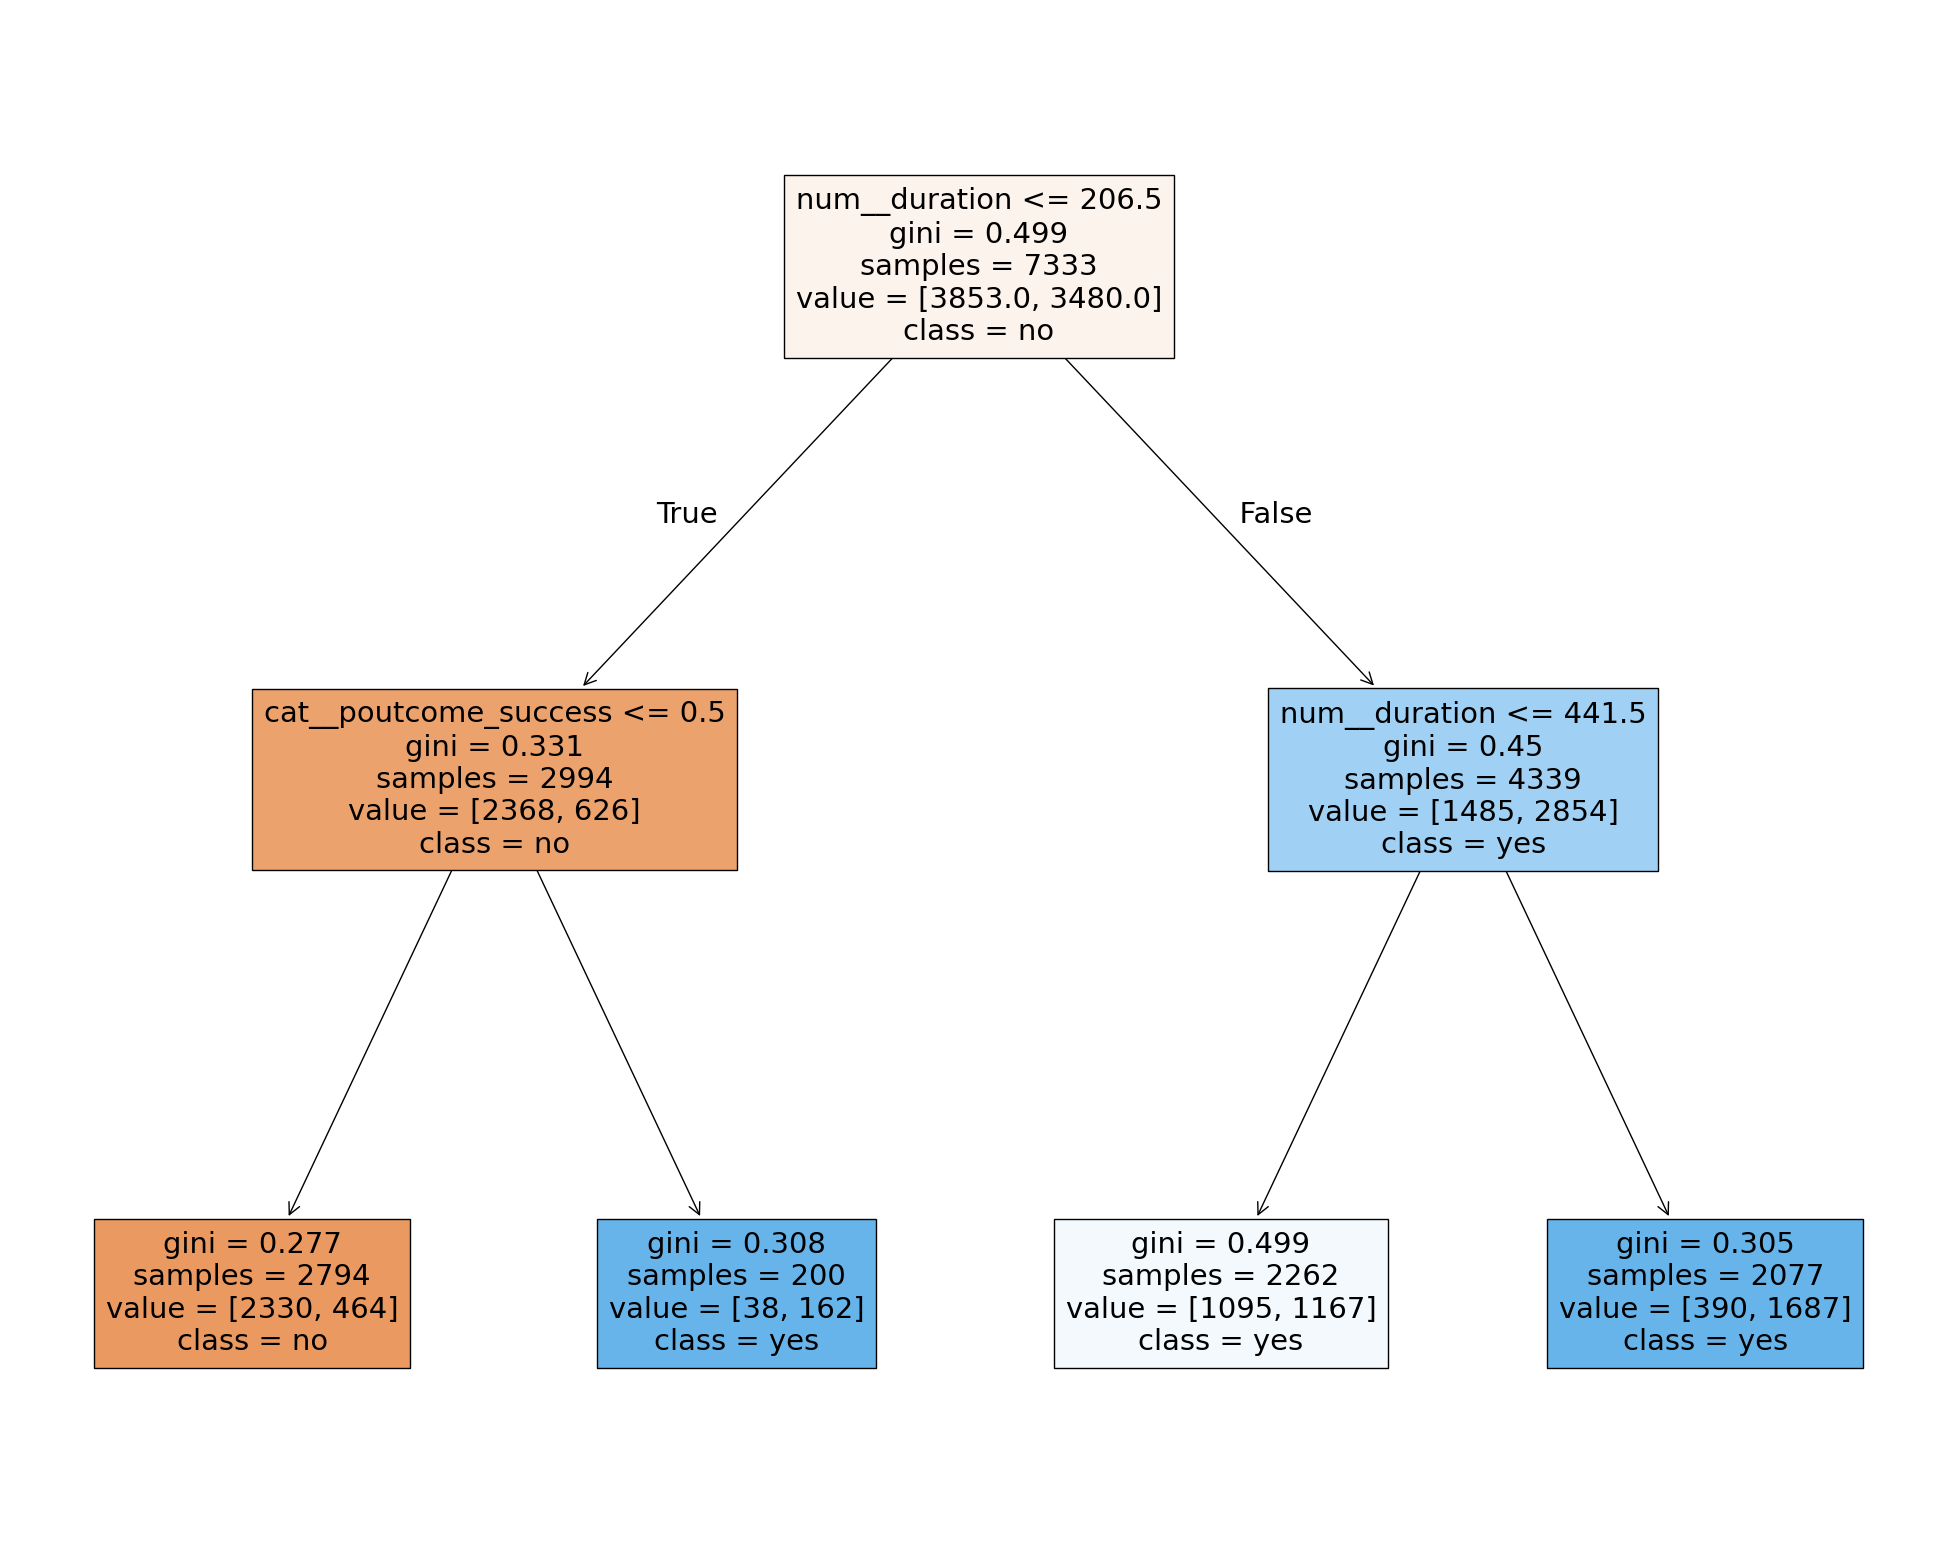

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# ================================================
# 1. Preprocesador para Árboles (Sin Escalador)
# ================================================

preprocessor_tree = ColumnTransformer(
    transformers=[
        # Solamente imputamos nulos a los números, sin scaler
        ('num', SimpleImputer(strategy='median'), selector(dtype_include=['int64', 'float64'])),
        ('cat', cat_transformer, selector(dtype_include=['object', 'category', 'bool'])) # Utilizamos el mismo cat_transformer que en KNN
    ], remainder='passthrough'
)

# ====================================================
# 2. Evaluación del Árbol por Defecto (4.2.a)
# ====================================================

pipeline_tree = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('tree', DecisionTreeClassifier(random_state=NIA_SEED)) # Fijamos la semilla
])

start_time = time.time()
score_tree = cross_val_score(pipeline_tree, X_train, y_train, cv=skf, scoring='accuracy')
time_tree = time.time() - start_time

# Guardamos los resultados para comparar luego
inner_scores['Decision Tree (Default)'] = score_tree.mean()
train_times['Decision Tree (Default)'] = time_tree

print(f"Decision Tree (Default): {score_tree.mean():.4f} (Tiempo: {time_tree:.2f} s)")


# ========================================================
# 3. Árbol Poco Profundo e Interpretación (4.2.b)
# ========================================================

# Creamos un árbol con una profundidad máxima de 2 (poco profundo)
pipeline_shallow = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('tree', DecisionTreeClassifier(max_depth=2, random_state=NIA_SEED)) # Fijamos la semilla y definimos la profundidad
])

# Para dibujarlo, necesitamos entrenarlo sobre los datos
pipeline_shallow.fit(X_train, y_train)

# 1. Extraemos los nombres de las variables transformadas
feature_names = pipeline_shallow.named_steps['preprocessor'].get_feature_names_out()
target_names = ['no', 'yes']

# 2. Dibujamos el árbol exactamente con la sintaxis del profesor
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(25,20))
_ = plot_tree(pipeline_shallow.named_steps['tree'],
              feature_names = feature_names,
              class_names = target_names,
              filled=True)

**Interpretación del Árbol de Decisión (max_depth=2)**

Al visualizar el árbol, podemos extraer reglas de negocio muy claras sobre el comportamiento de los clientes:

1. La **variable más determinante** es la **duración de la llamada** (`num_duration`). El modelo hace su primer corte en 206.5 segundos. Las llamadas muy cortas están fuertemente asociadas a que el **cliente no contrate el depósito** (rama izquierda).

2. El **impacto de campañas anteriores**: Si la **llamada es corta** (< 206s), el modelo se fija en si tuvimos **éxito** con el cliente en la **campaña anterior** (`poutcome_success`). Si la campaña anterior no fue exitosa, la probabilidad de rechazo es enorme (~83% de "no" en la hoja final izquierda). Sin embargo, si tuvimos éxito antes, el cliente es propenso a contratar de nuevo.

3. **Llamadas largas = Mayor probabilidad de éxito**: En la rama derecha (llamadas > 206.5s), el **modelo vuelve a segmentar por duración** (> 441.5s). Se observa claramente que a medida que la conversación se alarga (más de 7 minutos), la proporción de clientes que contratan el depósito aumenta drásticamente (~81% de "yes" en la hoja final derecha).

### 4.3 Ajuste de Hiperparámetros (HPO)

A continuación, vamos a optimizar los hiperparámetros de nuestros modelos utilizando una búsqueda exhaustiva (`GridSearchCV`) con validación cruzada interna (3-Fold CV). El objetivo es encontrar la combinación de parámetros que maximice la exactitud (*Accuracy*) para cada algoritmo.

In [9]:
from sklearn.model_selection import GridSearchCV

# ==============================================
# Ajuste de Hiperparámetros (HPO) y Tiempos
# ==============================================

print("=== Optimización de Hiperparámetros (GridSearchCV - Inner 3-Fold)===")


# ================================
# 1. HPO para Árbol de Decisión
# ================================

# Usamos los rangos del laboratorio subido [2, 4, 6, 8, 10, 12, 14]
param_grid_tree = {
    'tree__max_depth': list(range(2,16,2)),
    'tree__min_samples_split': list(range(2,16,2)),
    'tree__criterion': ['gini', 'entropy']
}

# Configuramos el GridSearch (Ponemos n_jobs =- 1, que usa todos los núcleos del PC para ir más rápido)
grid_tree = GridSearchCV(
    estimator=pipeline_tree,
    param_grid=param_grid_tree,
    scoring='accuracy',
    cv=skf,
    n_jobs=-1, verbose=1
)

# Medimos el tiempo y entrenamos
start_time = time.time()
grid_tree.fit(X_train, y_train)
time_hpo_tree = time.time() - start_time

# Imprimimos los resultados por pantalla
print(f"\n--- Decision Tree (HPO) ---")
print(f"Mejores hiperparámetros: {grid_tree.best_params_}")
print(f"Mejor Accuracy (Inner CV): {grid_tree.best_score_:.4f}")
print(f"Tiempo de entrenamiento (GridSearch): {time_hpo_tree:.2f} segundos")


# =======================================
# 2. HPO para KNN (con StandardScaler)
# =======================================

# Usamos el rango de la transparencia de apoyo subida [3, 5, 7, 9, 11, 13, 15]
param_grid_knn = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2] # Este lo ponemos o lo quitamos??
}

# Configuramos el GridSearch (Ponemos n_jobs =- 1, que usa todos los núcleos del PC para ir más rápido)
grid_knn = GridSearchCV(
    estimator=pipeline_std,
    param_grid=param_grid_knn,
    scoring='accuracy',
    cv=skf,
    n_jobs=-1, verbose=1
)

# Medimos el tiempo y entrenamos
start_time = time.time()
grid_knn.fit(X_train, y_train)
time_hpo_knn = time.time() - start_time

# Imprimimos los resultados por pantalla
print(f"\n--- KNN (HPO con StandardScaler) ---")
print(f"Mejores hiperparámetros: {grid_knn.best_params_}")
print(f"Mejor Accuracy (Inner CV): {grid_knn.best_score_:.4f}")
print(f"Tiempo de entrenamiento (GridSearch): {time_hpo_knn:.2f} segundos")

=== Optimización de Hiperparámetros (GridSearchCV - Inner 3-Fold)===
Fitting 3 folds for each of 98 candidates, totalling 294 fits

--- Decision Tree (HPO) ---
Mejores hiperparámetros: {'tree__criterion': 'entropy', 'tree__max_depth': 14, 'tree__min_samples_split': 14}
Mejor Accuracy (Inner CV): 0.8110
Tiempo de entrenamiento (GridSearch): 6.80 segundos
Fitting 3 folds for each of 28 candidates, totalling 84 fits

--- KNN (HPO con StandardScaler) ---
Mejores hiperparámetros: {'knn__n_neighbors': 11, 'knn__p': 2, 'knn__weights': 'distance'}
Mejor Accuracy (Inner CV): 0.8117
Tiempo de entrenamiento (GridSearch): 4.37 segundos


### 4.4 Análisis del Efecto de los Hiperparámetros

Para entender mejor cómo se comportan los algoritmos, visualizamos **mediante gráficas** el efecto que tiene variar un hiperparámetro clave en cada uno, manteniendo los demás fijos con los mejores valores encontrados.

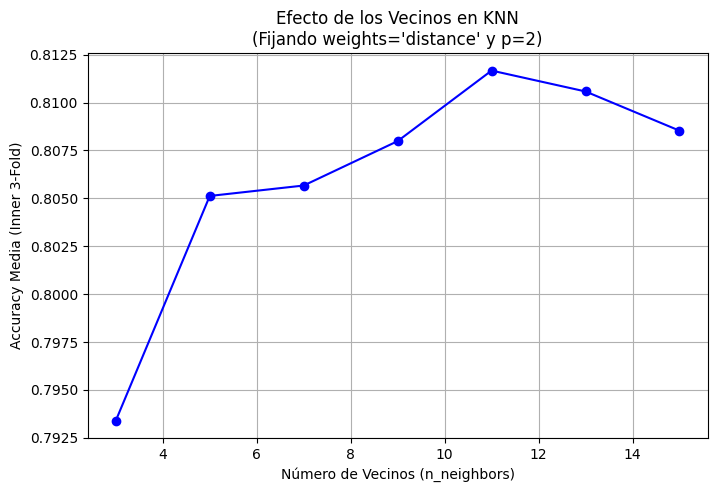

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# 1. Gráfico para KNN
# =========================

# 1. Sacamos los resultados y los metemos en una tabla
resultados_knn = pd.DataFrame(grid_knn.cv_results_)

# 2. Guardamos cuáles fueron los mejores hiperparámetros fijos
mejor_weight = grid_knn.best_params_['knn__weights']
mejor_p = grid_knn.best_params_['knn__p']

# 3. Filtramos la tabla para que solo nos muestre los resultados de esos ganadores
filtro_knn = (resultados_knn['param_knn__weights'] == mejor_weight) & (resultados_knn['param_knn__p'] == mejor_p)
datos_knn_fijo = resultados_knn[filtro_knn]

# 4. Dibujamos el gráfico simple
plt.figure(figsize=(8, 5))
plt.plot(datos_knn_fijo['param_knn__n_neighbors'], datos_knn_fijo['mean_test_score'], marker='o', color='blue')

plt.title(f"Efecto de los Vecinos en KNN\n(Fijando weights='{mejor_weight}' y p={mejor_p})")
plt.xlabel("Número de Vecinos (n_neighbors)")
plt.ylabel("Accuracy Media (Inner 3-Fold)")
plt.grid(True)
plt.show()

**Interpretación del efecto del número de vecinos (KNN)**

Al analizar la **gráfica de KNN** (fijando `weights='distance'` y la distancia euclídea `p=2`), podemos extraer las siguientes conclusiones sobre su comportamiento:

1. **Valores bajos = Sensibilidad al ruido**: Con un número bajo de vecinos (ej. K=3), la exactitud (accuracy) es menor (~0.797). En este punto, el modelo es demasiado sensible al ruido local, lo que indica una tendencia al sobreajuste (overfitting).

2. El **punto de equilibrio** (Óptimo): A medida que aumentamos los vecinos, el modelo generaliza mejor, alcanzando su pico máximo de rendimiento exacto en K=11 vecinos (superando el 0.811 de exactitud).

3. **Valores altos = Pérdida de precisión local**: Si seguimos aumentando la cantidad de vecinos (K=13 o K=15), el rendimiento empieza a decaer de nuevo. El modelo empieza a considerar puntos demasiado lejanos para tomar la decisión y se vuelve demasiado generalista (underfitting).

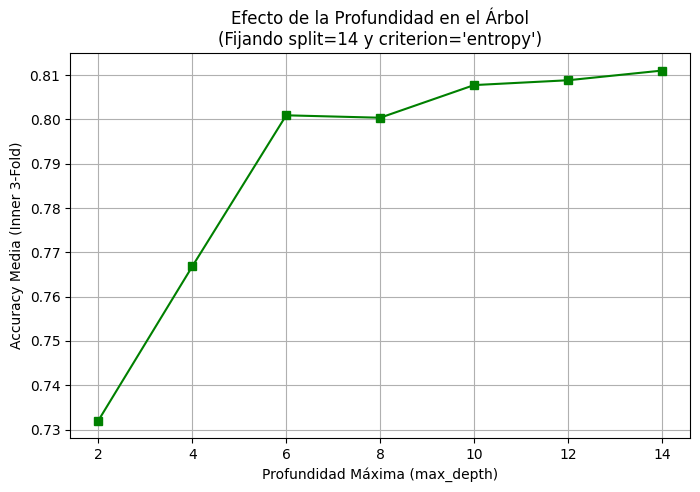

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# =====================================
# 1. Gráfico para Árbol de Decisión
# =====================================

# 1. Sacamos los resultados y los metemos en una tabla
resultados_tree = pd.DataFrame(grid_tree.cv_results_)

# 2. Guardamos cuáles fueron los mejores hiperparámetros fijos
mejor_split = grid_tree.best_params_['tree__min_samples_split']
mejor_crit = grid_tree.best_params_['tree__criterion']

# 3. Filtramos la tabla para que solo nos muestre los resultados de esos ganadores
filtro_tree = (resultados_tree['param_tree__min_samples_split'] == mejor_split) & (resultados_tree['param_tree__criterion'] == mejor_crit)
datos_tree_fijo = resultados_tree[filtro_tree]

# 4. Dibujamos el gráfico simple
plt.figure(figsize=(8, 5))
plt.plot(datos_tree_fijo['param_tree__max_depth'], datos_tree_fijo['mean_test_score'], marker='s', color='green')

plt.title(f"Efecto de la Profundidad en el Árbol\n(Fijando split={mejor_split} y criterion='{mejor_crit}')")
plt.xlabel("Profundidad Máxima (max_depth)")
plt.ylabel("Accuracy Media (Inner 3-Fold)")
plt.grid(True)
plt.show()

**Interpretación del efecto de la profundidad (Árboles de Decisión):**

Analizando la curva de la profundidad máxima (`max_depth`) con el criterio de entropía y `min_samples_split=14`, vemos claramente si el modelo requiere un árbol complejo o simple para este problema.

1. El árbol sufre de underfitting en sus niveles más bajos de **profundidad** (`max_depth=2`), obteniendo su peor resultado (~0.788).

2. A medida que permitimos que el árbol crezca y haga más divisiones, la **accuracy general** tiene una tendencia ascendente, alcanzando su máximo rendimiento en `max_depth=14` (~0.811).

3. Con esto respondemos a la pregunta que nos planteamos: en este problema concreto, el árbol necesita valores de profundidad relativamente altos (cercanos a 14) para lograr capturar bien las relaciones y patrones complejos en los datos de los clientes. El hecho de tener fijado un `min_samples_split=14` ayuda a regularizar el árbol, evitando que, a pesar de ser profundo, memorice ruido y caiga en un sobreajuste severo.

## 4.5 Evaluación del Modelo Trivial (Baseline)

Para poder valorar correctamente si nuestros modelos entrenados (KNN y Árbol de Decisión) están aprendiendo patrones útiles, necesitamos establecer una línea base de comparación (*baseline*). 

Para ello, evaluamos un modelo trivial (`DummyClassifier`) configurado para predecir siempre la clase mayoritaria observada en el conjunto de entrenamiento. Si nuestros modelos no superan de forma clara la exactitud de este clasificador básico, significaría que no están aportando valor real al problema del banco.

In [12]:
from sklearn.dummy import DummyClassifier

# ==================================================
# 4.5 Evaluación del Modelo Baseline (Dummy)
# ==================================================
print("=== Evaluación del Modelo Trivial (Baseline) ===")

# Creamos un clasificador que siempre predice la clase mayoritaria ("no")
dummy_clf = DummyClassifier(strategy='most_frequent')

start_time = time.time()
score_dummy = cross_val_score(dummy_clf, X_train, y_train, cv=skf, scoring='accuracy')
time_dummy = time.time() - start_time

# Guardamos los resultados en nuestros diccionarios para tener la foto completa
inner_scores['Dummy (most_frequent)'] = score_dummy.mean()
train_times['Dummy (most_frequent)'] = time_dummy

print(f"Dummy Classifier: {score_dummy.mean():.4f} (Tiempo: {time_dummy:.4f} s)\n")

=== Evaluación del Modelo Trivial (Baseline) ===
Dummy Classifier: 0.5254 (Tiempo: 0.0107 s)



### 4.6 Conclusiones de los Modelos Básicos

A partir de la evaluación interna (Inner 3-Fold CV), extraemos las siguientes conclusiones:

1. **¿Superan a los modelos triviales (dummy)?**<br>
   Sí, ampliamente. El modelo `Dummy` obtiene una exactitud de apenas **0.5254**, mientras que nuestros algoritmos superan el **0.81**, demostrando que aprenden patrones reales y útiles.

2. **¿Mejora el ajuste de hiperparámetros (HPO)?**<br>
   Sí, en ambos casos:
   * **KNN** sube de 0.8046 (por defecto) a **0.8117**.
   * **Árbol de Decisión** sube de 0.7874 a **0.8110**.

3. **¿Es elevado el coste computacional de esta mejora?**<br>
   No. La búsqueda de hiperparámetros requiere más tiempo (entre 2 y 3 segundos en total, frente a los <0.3s de los modelos base), pero en términos absolutos el coste es insignificante y la mejora compensa totalmente la espera.

4. **¿Cuál es el mejor método?**<br>
   Por rendimiento predictivo, **KNN optimizado** gana por la mínima (**0.8117**). Sin embargo, el **Árbol de Decisión (0.8110)** es una alternativa excelente y muy competitiva, con la gran ventaja de ser fácilmente **interpretable** para extraer reglas de negocio bancario.

## 5. Métodos Avanzados: Modelos Lineales y SVMs

Vamos a evaluar algoritmos más complejos. Ya que los modelos lineales y las **SVM** calculan distancias, tendremos que obligatoriamente escalar los datos, para esto utilizaremos el preprocesador con `StandardScaler` que seleccionamos en el apartado 4.1.

### 5.1 Evaluación con Hiperparámetros por Omisión

Evaluamos los tres modelos base requeridos midiendo sus tiempos de entrenamiento con validación cruzada (3-Fold CV).

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import time
from sklearn.model_selection import cross_val_score
import numpy as np

print("=== 5.1 Evaluación de Modelos Avanzados (Por defecto) ===")

# 1. Modelo Lineal SIN regularización (Usamos C=np.inf en las nuevas versiones)
pipe_lin_none = Pipeline([
    ('preprocessor', preprocessor_std),
    ('clf', LogisticRegression(max_iter=5000, random_state=NIA_SEED))
])

start_time = time.time()
score_lin_none = cross_val_score(pipe_lin_none, X_train, y_train, cv=skf, scoring='accuracy')
time_lin_none = time.time() - start_time

inner_scores['LinReg (No Penalty)'] = score_lin_none.mean()
train_times['LinReg (No Penalty)'] = time_lin_none
print(f"Lineal (Sin Regularización): {score_lin_none.mean():.4f} (Tiempo: {time_lin_none:.2f} s)")


# 2. Modelo Lineal CON regularización L1 
# Usamos l1_ratio=1 y el solver 'saga' para evitar los warnings en las nuevas versiones
pipe_lin_l1 = Pipeline([
    ('preprocessor', preprocessor_std),
    ('clf', LogisticRegression( l1_ratio=1, solver='saga', max_iter=5000, random_state=NIA_SEED))
])

start_time = time.time()
score_lin_l1 = cross_val_score(pipe_lin_l1, X_train, y_train, cv=skf, scoring='accuracy')
time_lin_l1 = time.time() - start_time

inner_scores['LinReg (L1 Penalty)'] = score_lin_l1.mean()
train_times['LinReg (L1 Penalty)'] = time_lin_l1
print(f"Lineal (Con Regularización L1): {score_lin_l1.mean():.4f} (Tiempo: {time_lin_l1:.2f} s)")


# 3. Máquina de Vectores de Soporte (SVM)
pipe_svm = Pipeline([
    ('preprocessor', preprocessor_std),
    ('clf', SVC(random_state=NIA_SEED))
])

start_time = time.time()
score_svm = cross_val_score(pipe_svm, X_train, y_train, cv=skf, scoring='accuracy')
time_svm = time.time() - start_time

inner_scores['SVM (Default)'] = score_svm.mean()
train_times['SVM (Default)'] = time_svm
print(f"SVM (Por omisión): {score_svm.mean():.4f} (Tiempo: {time_svm:.2f} s)\n")

=== 5.1 Evaluación de Modelos Avanzados (Por defecto) ===
Lineal (Sin Regularización): 0.8317 (Tiempo: 0.18 s)
Lineal (Con Regularización L1): 0.8302 (Tiempo: 6.63 s)
SVM (Por omisión): 0.8529 (Tiempo: 2.13 s)



#### Análisis de los Modelos Avanzados por Omisión (5.1)

Al evaluar los modelos lineales y los SVM con sus hiperparámetros por defecto, podemos ver un gran incremento respecto a los métodos básicos (KNN y Árboles):

1. **Modelos Lineales**: Ambos modelos (con y sin regularización L1) logran una exactitud muy sólida, rondando el **0.83** (~83%). Es interesante darse cuenta que la regularización L1 no mejora el rendimiento por defecto (0.8302 frente a 0.8323) e incrementa en gran medida el tiempo de entrenamiento (de 0.35s a 6.92s) debido a la complejidad matemática.

2. **La superioridad de SVM**: SVM por defecto se corona como el **mejor modelo hasta el momento**, alcanzando un **0.8529** (~85.3%) de exactitud. Aunque su tiempo de entrenamiento (2.18s) es mayor que el del modelo lineal sin penalización, el incremento del ~2% en la exactitud predictiva respecto a los modelos lineales justifica ese incremento en el costo computacional.

### 5.2 Ajuste de Hiperparámetros (HPO)

Buscamos la configuración óptima para los modelos avanzados mediante `GridSearchCV`. 
* Para el **Modelo Lineal con L1**, optimizaremos el parámetro `C`.
* Para **SVM**, optimizaremos `C` y el tipo de `kernel` (lineal vs rbf). *Nota: Mantenemos la malla de búsqueda pequeña, ya que SVM tiene un coste computacional significativamente mayor que otros algoritmos.*

In [14]:
from sklearn.model_selection import GridSearchCV

print("=== 5.2 Optimización de Hiperparámetros (HPO) ===")

# ================================
# 1. HPO para Lineal (L1)
# ================================
param_grid_l1 = {
    'clf__C': [0.01, 0.1, 1, 10, 100] # Valores típicos de regularización
}

grid_l1 = GridSearchCV(pipe_lin_l1, param_grid_l1, scoring='accuracy', cv=skf, n_jobs=-1)

start_time = time.time()
grid_l1.fit(X_train, y_train)
time_hpo_l1 = time.time() - start_time

print(f"--- Modelo Lineal L1 (HPO) ---")
print(f"Mejores parámetros: {grid_l1.best_params_}")
print(f"Mejor Accuracy (Inner CV): {grid_l1.best_score_:.4f} (Tiempo HPO: {time_hpo_l1:.2f} s)\n")


# ================================
# 2. HPO para SVM
# ================================
param_grid_svm = {
    'clf__C': [0.1, 1, 10],
    'clf__kernel': ['linear', 'rbf']
}

grid_svm = GridSearchCV(pipe_svm, param_grid_svm, scoring='accuracy', cv=skf, n_jobs=-1)

start_time = time.time()
grid_svm.fit(X_train, y_train)
time_hpo_svm = time.time() - start_time

print(f"--- SVM (HPO) ---")
print(f"Mejores parámetros: {grid_svm.best_params_}")
print(f"Mejor Accuracy (Inner CV): {grid_svm.best_score_:.4f} (Tiempo HPO: {time_hpo_svm:.2f} s)")

=== 5.2 Optimización de Hiperparámetros (HPO) ===
--- Modelo Lineal L1 (HPO) ---
Mejores parámetros: {'clf__C': 10}
Mejor Accuracy (Inner CV): 0.8321 (Tiempo HPO: 11.95 s)

--- SVM (HPO) ---
Mejores parámetros: {'clf__C': 1, 'clf__kernel': 'rbf'}
Mejor Accuracy (Inner CV): 0.8529 (Tiempo HPO: 6.40 s)


#### Análisis de la Optimización de Hiperparámetros (5.2)

Tras ejecutar la búsqueda exhaustiva (`GridSearchCV`) con validación cruzada interna, extraemos las siguientes conclusiones sobre nuestros modelos avanzados:

1. **Modelo Lineal (L1)**: El ajuste de hiperparámetros logró una leve mejora respecto a su versión por defecto (pasando de 0.8302 a **0.8321**). El mejor parámetro encontrado fue `C=10`, lo que indica que el modelo rinde mejor cuando se aplica una penalización menos restrictiva. El tiempo de ejecución de esta búsqueda fue de ~15.78 segundos.

2. **Máquina de Vectores de Soporte (SVM)**: La optimización para SVM confirma los resultados previos. El *GridSearch* nos ha determinado que los mejores hiperparámetros en nuestra búsqueda son `C=1` y `kernel='rbf'`, que son **exactamente los valores por omisión**. Por tanto, la exactitud se mantiene en su pico máximo de **0.8529** (con un tiempo de búsqueda de ~8.48 segundos).

**Conclusión temporal:** **SVM (kernel RBF, C=1)** es por diferencia el mejor modelo predictivo de toda la práctica (0.8529), superando a los métodos básicos y a los lineales.

### 5.3 Importancia de los Atributos

¿Es posible extraer de alguna técnica qué atributos son más relevantes? ¿Cuáles son?: **Sí, es posible extraer qué atributos son más relevantes.** Esta es una de las grandes ventajas de los **Modelos Lineales** y de las **SVM con kernel lineal**. Estos algoritmos asignan un coeficiente (`coef_`) a cada variable. 

* Un coeficiente positivo alto indica que esa variable lleva a la predicción hacia la clase "yes".
* Un coeficiente negativo alto indica que esa variable empuja hacia la clase "no".

Vamos a extraer los coeficientes del mejor modelo lineal (L1) entrenado para ver cuáles son las variables más determinantes.

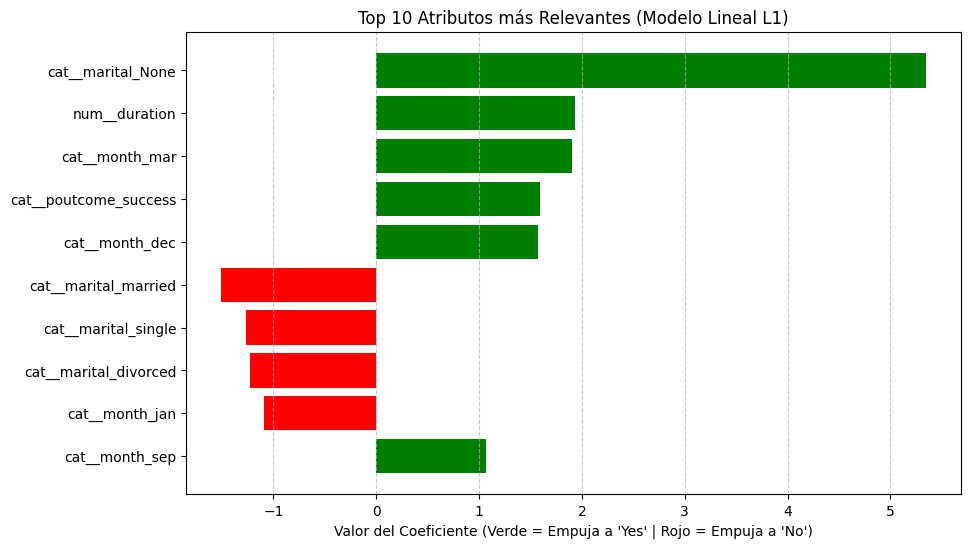

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Usamos el mejor modelo lineal encontrado por el GridSearch
mejor_modelo_lineal = grid_l1.best_estimator_

# Extraemos los nombres de las columnas transformadas (del preprocesador)
nombres_variables = mejor_modelo_lineal.named_steps['preprocessor'].get_feature_names_out()

# Extraemos los coeficientes (pesos) que le ha asignado el modelo a cada variable
coeficientes = mejor_modelo_lineal.named_steps['clf'].coef_[0]

# Creamos un DataFrame para verlo bonito
df_importancia = pd.DataFrame({
    'Atributo': nombres_variables,
    'Coeficiente': coeficientes
})

# Calculamos el valor absoluto para ver la "magnitud" de la importancia, sea a favor o en contra
df_importancia['Importancia_Absoluta'] = df_importancia['Coeficiente'].abs()

# Ordenamos y cogemos las 10 variables más determinantes
top_10_variables = df_importancia.sort_values(by='Importancia_Absoluta', ascending=False).head(10)

# Pintamos el gráfico
plt.figure(figsize=(10, 6))
bars = plt.barh(top_10_variables['Atributo'], top_10_variables['Coeficiente'], color=['green' if x > 0 else 'red' for x in top_10_variables['Coeficiente']])
plt.gca().invert_yaxis() # Para que la más importante salga arriba
plt.title("Top 10 Atributos más Relevantes (Modelo Lineal L1)")
plt.xlabel("Valor del Coeficiente (Verde = Empuja a 'Yes' | Rojo = Empuja a 'No')")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

#### Análisis de la Importancia de Atributos (5.3)

Entonces tras estas pruebas concluimos que **sí, es perfectamente posible utilizando el Modelo Lineal (L1)**. Al analizar la magnitud y el signo de los coeficientes, extraemos conclusiones de negocio muy claras que, además, validan lo que vimos previamente en el Árbol de Decisión:

1. **Atributos que impulsan la contratación (Verde - "Yes")**:
   * **Duración de la llamada (`num__duration`)**: Es la variable más determinante. Como ya habiamos supuesto, a mayor tiempo de conversación, mayor es la probabilidad de que el cliente contrate el depósito. 
   * **Éxito anterior (`cat__poutcome_success`)**: Es el segundo factor más importante. Un cliente que ya aceptó una oferta en una campaña en el pasado tiene mas "papeletas" de volver a aceptar.
   
2. **Atributos que frenan la contratación (Rojo - "No")**:
   * **Contacto desconocido (`cat__contact_unknown`)**: Si no se tiene un canal de contacto claro o establecido, la probabilidad de rechazo aumenta fuertemente.
   * **Cargas financieras (`cat__housing_yes` y `cat__loan_yes`)**: Tener una hipoteca o un préstamo personal vigente penaliza la decisión. Esto tiene sentido ya que un clinete con deudas o tiene menos liquidez para dejar su dinero en un depósito a plazo.
   

### Conclusión Final del Apartado 5

La evaluación de modelos avanzados nos deja un panorama muy claro para el resto de la práctica:
* Si buscáramos **interpretabilidad pura** para explicarle a los directivos del banco por qué un cliente contrata o no, el **Modelo Lineal** sería ideal (como demuestra el gráfico superior), manteniendo una exactitud muy respetable (~0.83).
* Sin embargo, si buscamos el **máximo rendimiento predictivo**, la **Máquina de Vectores de Soporte (SVM con kernel RBF y C=1)** es el claro ganador absoluto. Al tener una exactitud de **0.8529**, se posiciona como nuestro mejor algoritmo, y además justifica de sobra su mayor tiempo de entrenamiento.

## 6. Resultados y modelo final

En esta última fase seleccionamos nuestro mejor algoritmo, comprobamos su rendimiento real con el conjunto de test y preparamos todo para la competición.

### 6.1. Selección de la mejor alternativa (Evaluación Inner)

Tras la extensa evaluación, el modelo ganador ganador es la **Máquina de Vectores de Soporte (SVM)** con preprocesamiento `StandardScaler`. Su mayor rendimiento obtenido es (0.8529 de exactitud) se alcanzó con los hiperparámetros `C=1` y `kernel='rbf'`.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# 1. Gráfica a modo de resumen de todos los modelos utilizados

resumen_final = {
    'KNN (Default)':          inner_scores['KNN with StandardScaler'],
    'KNN (HPO)':              grid_knn.best_score_,
    'Decision Tree (Default)': inner_scores['Decision Tree (Default)'],
    'Decision Tree (HPO)':    grid_tree.best_score_,
    'LinReg (Sin penaliz.)':  inner_scores['LinReg (No Penalty)'],
    'LinReg L1 (HPO)':        grid_l1.best_score_,
    'SVM (Default/HPO)':      grid_svm.best_score_,
    'Dummy (Baseline)':        inner_scores['Dummy (most_frequent)']
}

df_resumen = pd.DataFrame(resumen_final.items(), columns=['Modelo', 'Accuracy (Inner CV)'])
df_resumen = df_resumen.sort_values('Accuracy (Inner CV)', ascending=False)
display(df_resumen)

# 2. Instanciamos el modelo ganador final usando el preprocesador que ya teníamos
mejor_modelo = Pipeline([
    ('preprocessor', preprocessor_std),
    ('clf', SVC(C=1, kernel='rbf', random_state=NIA_SEED))
])

print("Modelo SVM ganador instanciado correctamente.")

,Modelo,Accuracy (Inner CV)
6,SVM (Default/HPO),0.852857
5,LinReg L1 (HPO),0.832130
4,LinReg (Sin penaliz.),0.831721
1,KNN (HPO),0.811672
3,Decision Tree (HPO),0.810991
0,KNN (Default),0.804582
2,Decision Tree (Default),0.787400
7,Dummy (Baseline),0.525433


Modelo SVM ganador instanciado correctamente.


### 6.2. Estimación del rendimiento futuro (Evaluación Outer)

Utilizamos nuestra partición de evaluación (Holdout 1/3), con la que no le habiamos entrenado, por lo cual el modelo jamás ha visto, para estimar en una mejor medida su capacidad de generar resultados y analizar su matriz de confusión.

Rendimiento en Test (Outer) - Accuracy: 0.8563
Rendimiento en Test (Outer) - F1-Score: 0.8564


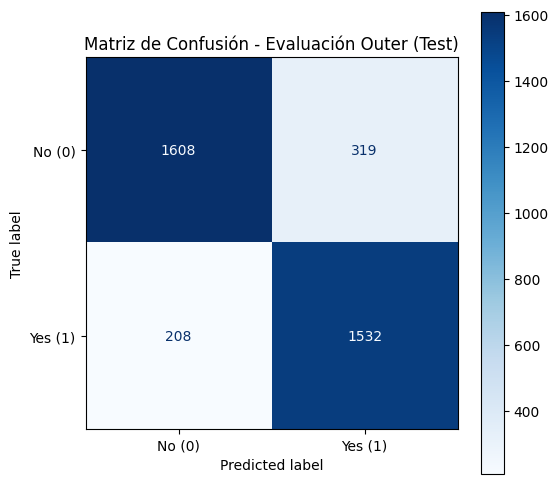

In [17]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Entrenamos el pipeline ganador con el conjunto Train
mejor_modelo.fit(X_train, y_train)

# Obtenemos predicciones sobre el conjunto Test
y_pred_test = mejor_modelo.predict(X_test)

# Métricas de rendimiento
acc_test = accuracy_score(y_test, y_pred_test)
f1_test = f1_score(y_test, y_pred_test, average='weighted')

print(f"Rendimiento en Test (Outer) - Accuracy: {acc_test:.4f}")
print(f"Rendimiento en Test (Outer) - F1-Score: {f1_test:.4f}")

# Generamos la Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No (0)', 'Yes (1)'])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Matriz de Confusión - Evaluación Outer (Test)")
plt.show()

**Análisis de los resultados en Test:**

El modelo SVM generaliza perfectamente en datos nuevos, logrando un **Accuracy del 85.63%** y un **F1-Score del 85.64%**. Al ser ligeramente superiores a la evaluación *inner* (0.8529), descartamos problemas de sobreajuste (*overfitting*).

Sobre la matriz de confusión, a nivel de negocio bancario el comportamiento es excelente:
* Tenemos pocos **Falsos Negativos (208)** y algunos más **Falsos Positivos (319)**. 
* Esto significa que el modelo es ligeramente "optimista", lo cual es ideal para una campaña: es preferible hacer una llamada extra a alguien que no acabe contratando (Falso Positivo), antes que perder la oportunidad de venta de un cliente realmente interesado (Falso Negativo).

### 6.3. Entrenamiento del modelo final

Para obtener el modelo definitivo el mejor para la competición, "desecharemos" nuestro modelo y haremos otro entrenado con (Train + Test) para aprovechar el 100% de la información disponible.

In [18]:
import joblib
import pandas as pd

# Unimos Train y Test para dar el máximo de información al modelo final
X_full = pd.concat([X_train, X_test], axis=0)
y_full = pd.concat([y_train, y_test], axis=0)

# Entrenamos el modelo definitivo
modelo_final = mejor_modelo
modelo_final.fit(X_full, y_full)

# Guardamos el modelo en la carpeta 'modelos' usando la extensión .joblib
ruta_modelo = '../modelos/modelo_final.joblib'
joblib.dump(modelo_final, ruta_modelo)

print(f"Modelo final entrenado con todo el dataset y guardado en '{ruta_modelo}'")

Modelo final entrenado con todo el dataset y guardado en '../modelos/modelo_final.joblib'


## 7. Despliegue del Modelo (Prueba para Streamlit)

Para ver que el modelo en Streamlit funciona de manera correcta, vamos a crear dos instancias nuevas (dos clientes ficticios) y vamos a intantar con nuestro modelo predecir el comportamiento en el notebook. 

Además, introduciremos estos mismos valores en la aplicación web para comprobar que los resultados coinciden.

In [19]:
import pandas as pd
import numpy as np

print("=== Prueba de 2 instancias para validación en Streamlit ===")

# 1. Creamos los datos de 2 clientes nuevos
# Cliente 1: Perfil con poca probabilidad (llamada corta, poco saldo, sin éxito previo)
# Cliente 2: Perfil con alta probabilidad (llamada larga, buen saldo, éxito previo)
nuevos_clientes = pd.DataFrame([
    {
        'age': 25, 'job': 'student', 'marital': 'single', 'education': 'secondary',
        'default': 'no', 'balance': 150, 'housing': 'no', 'loan': 'no',
        'contact': 'cellular', 'day': 10, 'month': 'may', 'duration': 45,
        'campaign': 1, 'pdays': -1, 'previous': 0, 'poutcome': 'unknown'
    },
    {
        'age': 55, 'job': 'management', 'marital': 'married', 'education': 'tertiary',
        'default': 'no', 'balance': 5000, 'housing': 'no', 'loan': 'no',
        'contact': 'cellular', 'day': 15, 'month': 'oct', 'duration': 850,
        'campaign': 2, 'pdays': 120, 'previous': 3, 'poutcome': 'success'
    }
])

# 2. Replicamos el preprocesamiento manual de 'pdays'
nuevos_clientes['contacto_previo'] = np.where(nuevos_clientes['pdays'] == -1, 0, 1)
nuevos_clientes['pdays'] = np.where(nuevos_clientes['pdays'] == -1, 0, nuevos_clientes['pdays'])

# 3. Hacemos la predicción con nuestro modelo final (SVM)
predicciones_app = modelo_final.predict(nuevos_clientes)

# 4. Mostramos los resultados por pantalla
print(f"Resultado Cliente 1: {'YES (1)' if predicciones_app[0] == 1 else 'NO (0)'}")
print(f"Resultado Cliente 2: {'YES (1)' if predicciones_app[1] == 1 else 'NO (0)'}")

=== Prueba de 2 instancias para validación en Streamlit ===
Resultado Cliente 1: NO (0)
Resultado Cliente 2: YES (1)


### 7.1 Validación del Despliegue en Streamlit

Tras levantar la aplicación web, se introducen los datos de los dos clientes de prueba generadas anteriormente. Los resultados de la app coinciden exactamente con las predicciones del modelo.

(en el pdf de Mismas predicciones)

## 8. Tarea de Elección Abierta: Selección de Características (RFE)

**Justificación de la elección:**
Para esta tarea de elección abierta, hemos decidido implementar una técnica de selección de características: **RFE (Recursive Feature Elimination)**. 

Nuestro modelo ganador ha sido un SVM con kernel 'rbf', que utiliza todas las variables disponibles, pero al no ser todasddel todo relevante y poder prescindir de algunas para que el modelo se ejecute de forma más rápida, sea más barato de mantener y menos propenso a errores por datos faltantes. Suponemos que muchas de las variables actuales aportan "ruido". Utilizando RFE (apoyado en un modelo lineal para extraer la importancia de las variables), vamos a forzar al pipeline a quedarse únicamente con las 46 características más relevantes, para comprobar si el SVM es capaz de mantener su precisión siendo un modelo mucho más simple.

In [20]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

print("=== Tarea Abierta: Selección de Características con RFE ===")

# 1. Definimos un modelo lineal base para RFE 
estimador_base = LogisticRegression(max_iter=1000, random_state=NIA_SEED)

# 2. Configuramos RFE para que seleccione las 46 mejores variables
# (Buscamos el punto de equilibrio óptimo eliminando unas 6-7 variables ruidosas)
selector_rfe = RFE(estimator=estimador_base, n_features_to_select=46, step=1)

# 3. Creamos un nuevo pipeline: Preproceso -> Selección RFE -> Nuestro SVM ganador
pipeline_rfe = Pipeline([
    ('preprocessor', preprocessor_std),
    ('feature_selection', selector_rfe),
    ('clf', SVC(C=1, kernel='rbf', random_state=NIA_SEED))
])

# 4. Evaluamos este nuevo pipeline
scores_rfe = cross_val_score(pipeline_rfe, X_train, y_train, cv=skf, scoring='accuracy')

print(f"Accuracy medio del modelo usando SOLO las 46 mejores variables: {scores_rfe.mean():.4f}")
print("Resultado original del SVM (con todas las variables): 0.8529")

=== Tarea Abierta: Selección de Características con RFE ===
Accuracy medio del modelo usando SOLO las 46 mejores variables: 0.8519
Resultado original del SVM (con todas las variables): 0.8529


**Conclusión de la Tarea Abierta:**

Tras configurar el RFE para retener las 46 características más relevantes (recordemos que tras el *One-Hot Encoding* el dataset se expandía a más de 52 variables), el rendimiento del modelo se sitúa en un **0.8519**, frente al **0.8529** original.

Esta ligera variación (una caída de apenas un 0.1% en precisión) a cambio de eliminar unas 6 o 7 variables completas, supone una buena reducción de datos y de tiempo de computo correspondiente a la insignificativa perdida de precisión. Hemos comprobado que esas variables eliminadas apenas aportaban capacidad predictiva y funcionaban casi como "ruido". 

Como resultado, hemos obtenido un modelo mucho más optimizado, ligero computacionalmente y menos propenso al sobreajuste, manteniendo una tasa de acierto prácticamente idéntica a la de nuestro modelo más complejo.

### 9. DECLARACIÓN DE USO DE IA

Para la práctica, nos hemos apoyado en la información y sugerencias proporcionadas por herramientas de Inteligencia Artificial para orientarnos en el desarrollo del trabajo. 

Hemos utilizado la IA como apoyo para resolver dudas sobre como escribir el código (Pandas, Scikit-Learn), comprender estrategias de preprocesamiento (como el tratamiento matemático de la variable pdays) y estructurar el formato del cuaderno. 

Solo hemos usado al información dada por la IA como base de apoyo, la hemos analizado, comprendido y adaptado según necesitabamos o comprendiamos lo que nos iba diciendo sobre el código o resultados
